# Analyse du corpus et proposition de partition

**Projet multimédia — M2 SID**

Objectifs : vérifier les données, décrire les déséquilibres et proposer une partition par film de **250 / 50 / 50 films**.

La partition produite est utilisée pour cette étude. Les mêmes listes seront conservées pour comparer les modèles dans les expériences suivantes. Les fichiers audio, vidéo et JSON d'origine restent à leur emplacement.

Ce notebook fonctionne localement. Il lit les annotations, sans décoder ni charger les vidéos en mémoire. Exécuter les cellules dans l'ordre.

## 1. Environnement et chemins

Dépendances : `numpy`, `pandas`, `matplotlib`. Si nécessaire, les installer dans l'environnement du notebook avec `%pip install numpy pandas matplotlib`.

Le dossier `PROJET_SID_2026` est recherché dans le répertoire courant et ses parents. Il peut également être indiqué explicitement dans la cellule suivante.

In [1]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import hashlib
import json
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("default")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

# Indiquer un chemin ici si le dossier n'est pas dans les répertoires parents.
chemin_donnees = None
if chemin_donnees is None:
    bases = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    candidats = [base / "PROJET_SID_2026" for base in bases]
    dossier_donnees = next((p for p in candidats if (p / "movie" / "annotation").is_dir()), None)
    if dossier_donnees is None:
        raise FileNotFoundError("Indiquer le chemin du dossier PROJET_SID_2026 dans chemin_donnees.")
else:
    dossier_donnees = Path(chemin_donnees).expanduser().resolve()

racine_depot = dossier_donnees.parent / "reconnaissance-emotions"
dossier_resultats = racine_depot / "resultats" / "analyse_donnees"
dossier_partition = racine_depot / "partitions" / "candidate_20261019"
dossier_docs = racine_depot / "docs"
for dossier in [dossier_resultats, dossier_partition, dossier_docs]:
    dossier.mkdir(parents=True, exist_ok=True)

emotions = ["amusement", "awe", "contentment", "excitement", "anger", "disgust", "fear", "sadness"]
noms_ensembles = ["apprentissage", "developpement", "test"]
print("Données :", dossier_donnees)
print("Python :", platform.python_version())
print("NumPy :", np.__version__, "| pandas :", pd.__version__, "| matplotlib :", matplotlib.__version__)

Données : /Users/lihanchen/Desktop/M2/DM_Projet/PROJET_SID_2026
Python : 3.11.7
NumPy : 1.26.4 | pandas : 2.1.4 | matplotlib : 3.8.0


## 2. Lire les annotations : une ligne par extrait

Le champ `emotion` est la **cible à prédire**, jamais une caractéristique d'entrée du modèle. L'identifiant du film est obtenu à partir du dossier contenant l'annotation. Les autres champs sont conservés pour l'analyse.

La lecture parallèle des petits fichiers JSON évite une lecture séquentielle inutilement lente. Toute annotation illisible est signalée et empêche la suite de l'analyse.

In [2]:
fichiers_json = sorted((dossier_donnees / "movie" / "annotation").glob("*/*.json"))
if not fichiers_json:
    raise ValueError("Aucune annotation trouvée.")

def lire_annotation(fichier):
    contenu = fichier.read_bytes()
    annotation = json.loads(contenu)
    if not isinstance(annotation, dict):
        raise ValueError(f"Annotation non valide : {fichier}")
    ligne = dict(annotation)
    ligne["film_id"] = fichier.parent.name
    ligne["nom_fichier"] = fichier.stem
    ligne["annotation"] = fichier.relative_to(dossier_donnees).as_posix()
    ligne["sha256_annotation"] = hashlib.sha256(contenu).hexdigest()
    return ligne

with ThreadPoolExecutor(max_workers=16) as executeur:
    lignes = list(executeur.map(lire_annotation, fichiers_json))

donnees = pd.DataFrame(lignes).sort_values(["film_id", "video_id"]).reset_index(drop=True)
print(f"{len(donnees):,} extraits et {donnees['film_id'].nunique()} films chargés.")
display(donnees[["video_id", "film_id", "emotion", "duration", "caption"]].head())

3,088 extraits et 350 films chargés.


,video_id,film_id,emotion,duration,caption
0,00000_clip_001,00000,anger,5.00,The video shows a man with red hair wearing a ...
1,00000_clip_002,00000,anger,6.21,"In the video, a man in a blue shirt and black ..."
2,00000_clip_006,00000,contentment,7.38,The video shows two men standing on a tennis c...
3,00000_clip_009,00000,anger,4.80,"In the video, two men are standing in front of..."
4,00000_clip_012,00000,anger,5.25,"In the video, a man in a blue shirt and a man ..."


## 3. Vérifier la qualité et la correspondance des fichiers

Vérifications : identifiants uniques, catégories attendues, durées positives et finies, descriptions présentes, et correspondance entre JSON, MP3 et MP4. Cette vérification porte sur les noms et les chemins ; elle ne vérifie pas le décodage des médias.

In [3]:
champs_attendus = ["video_id", "emotion", "duration", "caption", "brightness", "colorfulness", "hue"]
champs_absents = sorted(set(champs_attendus) - set(donnees.columns))
assert not champs_absents, f"Champs absents : {champs_absents}"

durees_numeriques = pd.to_numeric(donnees["duration"], errors="coerce")
controles = {
    "identifiants_dupliques": int(donnees["video_id"].duplicated().sum()),
    "identifiants_incoherents": int(donnees["video_id"].ne(donnees["nom_fichier"]).sum()),
    "labels_manquants": int(donnees["emotion"].isna().sum()),
    "labels_inconnus": int((~donnees["emotion"].isin(emotions)).sum()),
    "durees_invalides": int((~np.isfinite(durees_numeriques) | durees_numeriques.le(0)).sum()),
    "descriptions_vides": int(donnees["caption"].fillna("").astype(str).str.strip().eq("").sum()),
}
cles_annotations = set(zip(donnees["film_id"], donnees["video_id"]))
for type_media, extension in [("audio", ".mp3"), ("video", ".mp4")]:
    fichiers_media = sorted((dossier_donnees / "movie" / type_media).glob(f"*/*{extension}"))
    cles_media = {(p.parent.name, p.stem) for p in fichiers_media}
    controles[f"{type_media}_manquants"] = len(cles_annotations - cles_media)
    controles[f"{type_media}_sans_annotation"] = len(cles_media - cles_annotations)

display(pd.Series(controles, name="nombre").to_frame())
controles_bloquants = {k: v for k, v in controles.items() if k != "descriptions_vides" and v}
assert not controles_bloquants, f"Données à vérifier avant partition : {controles_bloquants}"
donnees["duration"] = durees_numeriques
print("Contrôles structurels réussis. Les descriptions vides éventuelles doivent être prises en compte pour le texte.")
print(f"Effectif observé : {len(donnees)} extraits ; effectif annoncé dans le support : 3439.")
if len(donnees) != 3439:
    print("Écart à signaler : sa cause ne peut pas être déterminée à partir de ce seul dossier.")

,nombre
identifiants_dupliques,0
identifiants_incoherents,0
labels_manquants,0
labels_inconnus,0
durees_invalides,0
descriptions_vides,0
audio_manquants,0
audio_sans_annotation,0
video_manquants,0
video_sans_annotation,0


Contrôles structurels réussis. Les descriptions vides éventuelles doivent être prises en compte pour le texte.
Effectif observé : 3088 extraits ; effectif annoncé dans le support : 3439.
Écart à signaler : sa cause ne peut pas être déterminée à partir de ce seul dossier.


## 4. Répartition globale des émotions

Un corpus équilibré aurait des effectifs proches entre les huit classes. On mesure ici les effectifs, les proportions et le rapport entre la classe la plus représentée et la moins représentée.

,nombre_extraits,proportion_pct
emotion,,
amusement,244,7.90
awe,286,9.26
contentment,373,12.08
excitement,354,11.46
anger,677,21.92
disgust,297,9.62
fear,519,16.81
sadness,338,10.95


Rapport classe majoritaire / minoritaire : 2.77


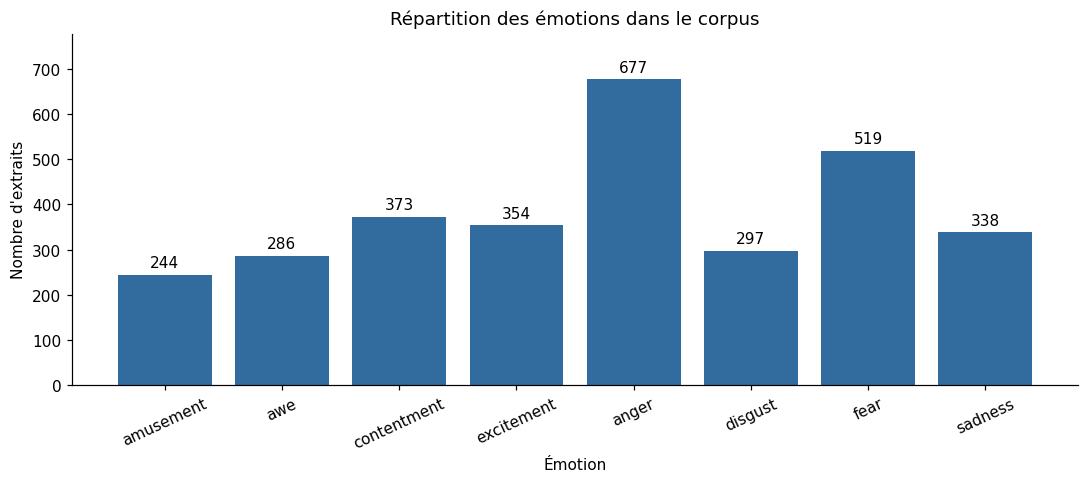

In [4]:
effectifs = donnees["emotion"].value_counts().reindex(emotions, fill_value=0)
repartition_globale = pd.DataFrame({"nombre_extraits": effectifs,
                                    "proportion_pct": effectifs / len(donnees) * 100})
repartition_globale.index.name = "emotion"
rapport_desequilibre = float(effectifs.max() / effectifs.min()) if effectifs.min() else float("inf")
display(repartition_globale.round(2))
print(f"Rapport classe majoritaire / minoritaire : {rapport_desequilibre:.2f}")

fig, ax = plt.subplots()
barres = ax.bar(emotions, effectifs, color="#326b9e")
ax.bar_label(barres, padding=3)
ax.set(title="Répartition des émotions dans le corpus", ylabel="Nombre d'extraits", xlabel="Émotion")
ax.tick_params(axis="x", rotation=25)
ax.margins(y=0.15)
fig.tight_layout()
fig.savefig(dossier_resultats / "01_effectifs_emotions.png", dpi=160)
plt.show()

## 5. Durées des extraits et contribution de chaque film

Le nombre de films ne suffit pas à décrire la taille d'un ensemble : chaque film peut fournir un nombre différent d'extraits et une durée totale différente. On analyse donc aussi ces deux aspects.

,duree_s
count,3088.000
mean,8.142
std,4.737
min,4.000
25%,4.960
50%,6.420
75%,9.433
95%,18.612
max,29.820


,nombre_extraits,duree_totale_s
count,350.00,350.00
mean,8.82,71.83
std,3.43,29.63
min,2.00,13.02
25%,6.00,50.12
50%,8.00,69.99
75%,11.00,90.68
max,22.00,181.20


Durée cumulée : 6.98 heures.


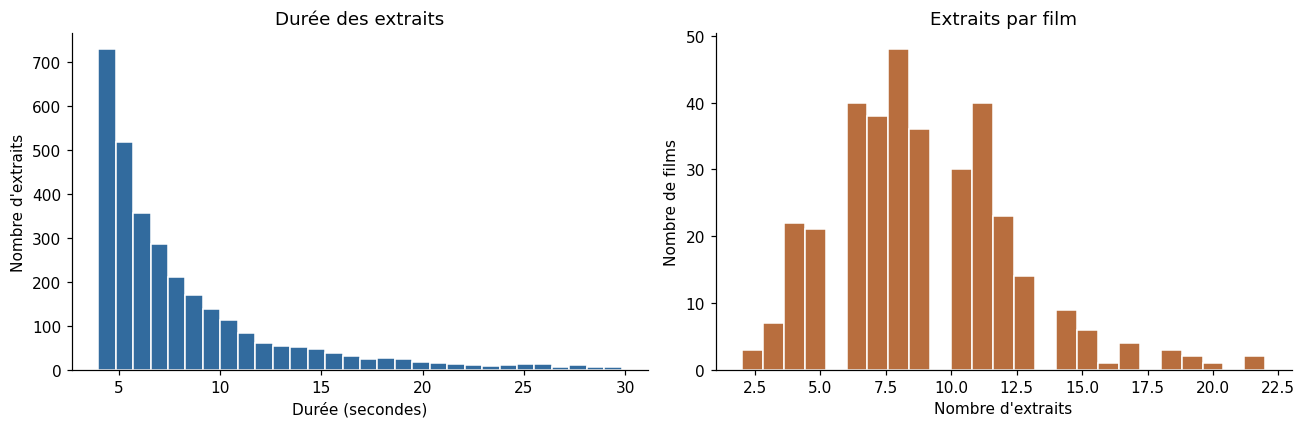

,count,mean,median,min,max
emotion,,,,,
amusement,244,7.86,6.51,4.00,29.82
awe,286,8.17,6.36,4.00,29.57
contentment,373,8.39,6.84,4.05,29.15
excitement,354,8.18,6.42,4.00,27.94
anger,677,7.69,6.05,4.00,29.02
disgust,297,8.10,6.71,4.00,25.56
fear,519,8.05,6.34,4.00,29.52
sadness,338,9.09,6.88,4.00,28.98


In [5]:
nombre_par_film = donnees.groupby("film_id").size().rename("nombre_extraits")
duree_par_film = donnees.groupby("film_id")["duration"].sum().rename("duree_totale_s")
resume_films = pd.concat([nombre_par_film, duree_par_film], axis=1)
statistiques_durees = donnees["duration"].describe(percentiles=[0.25, 0.5, 0.75, 0.95])
display(statistiques_durees.to_frame("duree_s").round(3))
display(resume_films.describe().round(2))
print(f"Durée cumulée : {donnees['duration'].sum() / 3600:.2f} heures.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(donnees["duration"], bins=30, color="#326b9e", edgecolor="white")
axes[0].set(title="Durée des extraits", xlabel="Durée (secondes)", ylabel="Nombre d'extraits")
axes[1].hist(nombre_par_film, bins=25, color="#b86e3e", edgecolor="white")
axes[1].set(title="Extraits par film", xlabel="Nombre d'extraits", ylabel="Nombre de films")
fig.tight_layout()
fig.savefig(dossier_resultats / "02_durees_et_films.png", dpi=160)
plt.show()

statistiques_par_emotion = donnees.groupby("emotion")["duration"].agg(["count", "mean", "median", "min", "max"]).reindex(emotions)
display(statistiques_par_emotion.round(2))

## 6. Préparer une partition par film

Chaque ligne du tableau suivant représente un film ; les colonnes donnent ses effectifs par émotion. Tous les extraits d'un film seront affectés au même ensemble.

Les tailles de 250 / 50 / 50 portent sur les **films**, pas sur les extraits. Aucun extrait n'est supprimé ou dupliqué pour équilibrer les classes.

In [6]:
table_films = pd.crosstab(donnees["film_id"], donnees["emotion"]).reindex(columns=emotions, fill_value=0).sort_index()
assert len(table_films) == 350, "La partition 250/50/50 nécessite exactement 350 films."
assert (table_films.sum() > 0).all(), "Une émotion attendue est absente du corpus."
display(table_films.head())
print("Nombre de films contenant chaque émotion :")
display(table_films.gt(0).sum().rename("nombre_films").to_frame())

emotion,amusement,awe,contentment,excitement,anger,disgust,fear,sadness
film_id,,,,,,,,
00000,0,0,1,1,11,1,3,0
00002,0,1,2,1,10,0,0,0
00003,1,0,0,0,4,2,0,1
00004,0,0,0,0,3,0,3,5
00005,2,1,0,2,2,0,0,4


Nombre de films contenant chaque émotion :


,nombre_films
emotion,
amusement,96
awe,120
contentment,140
excitement,151
anger,223
disgust,146
fear,171
sadness,133


## 7. Chercher une proposition reproductible

Méthode : partir de plusieurs partitions aléatoires, puis échanger des films entre ensembles lorsqu'un échange améliore le critère. Le nombre de films dans chaque ensemble reste inchangé.

Le critère privilégie des proportions proches de **1/8 par classe dans le développement et le test**. Il tient aussi compte de l'écart de l'apprentissage à la distribution globale et évite des tailles en extraits trop éloignées du ratio 250/50/50. Une classe absente est fortement pénalisée.

Ces choix définissent le critère retenu pour cette étude. La recherche est heuristique : elle ne garantit pas l'optimum ni une égalité parfaite des classes. Elle utilise uniquement les annotations pour construire la partition, sans consulter les performances d'un modèle sur le test.

In [7]:
graine = 20261019
nombre_departs = 24
nombre_echanges = 3000
generateur = np.random.default_rng(graine)
matrice = table_films.to_numpy(dtype=int)
identifiants_films = table_films.index.to_numpy()
tailles_films = np.array([250, 50, 50])
proportions_globales = matrice.sum(axis=0) / matrice.sum()
cibles_extraits = matrice.sum() * tailles_films / tailles_films.sum()


def score_partition(comptages):
    tailles = comptages.sum(axis=1)
    proportions = comptages / np.maximum(tailles[:, None], 1)
    ecart_dev_test = np.square(proportions[1:] - 1 / len(emotions)).sum()
    ecart_apprentissage = np.square(proportions[0] - proportions_globales).sum()
    ecart_tailles = np.square((tailles - cibles_extraits) / cibles_extraits).sum()
    classes_absentes = (comptages == 0).sum()
    return float(ecart_dev_test + 0.25 * ecart_apprentissage + 0.05 * ecart_tailles + 100 * classes_absentes)


def ameliorer_partition(groupes):
    groupes = [g.copy() for g in groupes]
    comptages = np.array([matrice[g].sum(axis=0) for g in groupes])
    score = score_partition(comptages)
    for _ in range(nombre_echanges):
        a, b = generateur.choice(3, size=2, replace=False)
        i = int(generateur.integers(len(groupes[a])))
        j = int(generateur.integers(len(groupes[b])))
        film_a, film_b = groupes[a][i], groupes[b][j]
        difference = matrice[film_b] - matrice[film_a]
        nouveaux_comptages = comptages.copy()
        nouveaux_comptages[a] += difference
        nouveaux_comptages[b] -= difference
        nouveau_score = score_partition(nouveaux_comptages)
        if nouveau_score < score - 1e-12:
            groupes[a][i], groupes[b][j] = film_b, film_a
            comptages, score = nouveaux_comptages, nouveau_score
    return groupes, comptages, score

# Une partition aléatoire simple sert de point de comparaison.
ordre_initial = generateur.permutation(len(table_films))
groupes_aleatoires = list(np.split(ordre_initial, [250, 300]))
comptages_aleatoires = np.array([matrice[g].sum(axis=0) for g in groupes_aleatoires])
meilleur_score = float("inf")
for depart in range(nombre_departs):
    ordre = ordre_initial if depart == 0 else generateur.permutation(len(table_films))
    groupes, comptages, score = ameliorer_partition(list(np.split(ordre, [250, 300])))
    if score < meilleur_score:
        meilleurs_groupes, meilleurs_comptages, meilleur_score = groupes, comptages, score

print(f"Graine : {graine} ; départs : {nombre_departs} ; échanges tentés par départ : {nombre_echanges}")
print(f"Critère aléatoire : {score_partition(comptages_aleatoires):.6f}")
print(f"Critère proposé  : {meilleur_score:.6f} (plus petit = meilleur selon ce critère)")

Graine : 20261019 ; départs : 24 ; échanges tentés par départ : 3000
Critère aléatoire : 0.047585
Critère proposé  : 0.000607 (plus petit = meilleur selon ce critère)


## 8. Contrôler et comparer les ensembles

On vérifie le nombre de films, l'absence de recouvrement et la couverture complète du corpus. Les statistiques ci-dessous permettent de juger les déséquilibres restant après la recherche.

In [8]:
affectation_films = {}
for nom, groupe in zip(noms_ensembles, meilleurs_groupes):
    for film_id in identifiants_films[groupe]:
        assert film_id not in affectation_films
        affectation_films[film_id] = nom

donnees["ensemble"] = donnees["film_id"].map(affectation_films)
assert donnees["ensemble"].notna().all()
assert donnees.groupby("film_id")["ensemble"].nunique().eq(1).all()
assert donnees.groupby("ensemble")["film_id"].nunique().reindex(noms_ensembles).tolist() == [250, 50, 50]
assert len(affectation_films) == 350

resume_ensembles = donnees.groupby("ensemble").agg(
    nombre_films=("film_id", "nunique"), nombre_extraits=("video_id", "size"),
    duree_totale_s=("duration", "sum"), duree_moyenne_s=("duration", "mean")
).reindex(noms_ensembles)
effectifs_ensembles = pd.crosstab(donnees["ensemble"], donnees["emotion"]).reindex(index=noms_ensembles, columns=emotions, fill_value=0)
proportions_ensembles = effectifs_ensembles.div(effectifs_ensembles.sum(axis=1), axis=0) * 100
assert effectifs_ensembles.gt(0).all().all(), "Une classe manque dans un ensemble."
display(resume_ensembles.round(2))
print("Effectifs par émotion :")
display(effectifs_ensembles)
print("Proportions par émotion (%) :")
display(proportions_ensembles.round(2))

proportions_aleatoires = comptages_aleatoires / comptages_aleatoires.sum(axis=1, keepdims=True) * 100
comparaison = pd.DataFrame({
    "ecart_moyen_uniforme_aleatoire_points": np.abs(proportions_aleatoires - 12.5).mean(axis=1),
    "ecart_moyen_uniforme_propose_points": np.abs(proportions_ensembles.to_numpy() - 12.5).mean(axis=1),
}, index=noms_ensembles)
comparaison.index.name = "ensemble"
display(comparaison.round(2))

,nombre_films,nombre_extraits,duree_totale_s,duree_moyenne_s
ensemble,,,,
apprentissage,250,2213,18022.13,8.14
developpement,50,437,3516.26,8.05
test,50,438,3602.81,8.23


Effectifs par émotion :


emotion,amusement,awe,contentment,excitement,anger,disgust,fear,sadness
ensemble,,,,,,,,
apprentissage,135,178,263,245,566,189,408,229
developpement,54,54,55,55,55,54,55,55
test,55,54,55,54,56,54,56,54


Proportions par émotion (%) :


emotion,amusement,awe,contentment,excitement,anger,disgust,fear,sadness
ensemble,,,,,,,,
apprentissage,6.10,8.04,11.88,11.07,25.58,8.54,18.44,10.35
developpement,12.36,12.36,12.59,12.59,12.59,12.36,12.59,12.59
test,12.56,12.33,12.56,12.33,12.79,12.33,12.79,12.33


,ecart_moyen_uniforme_aleatoire_points,ecart_moyen_uniforme_propose_points
ensemble,,
apprentissage,3.18,4.75
developpement,4.28,0.11
test,4.78,0.17


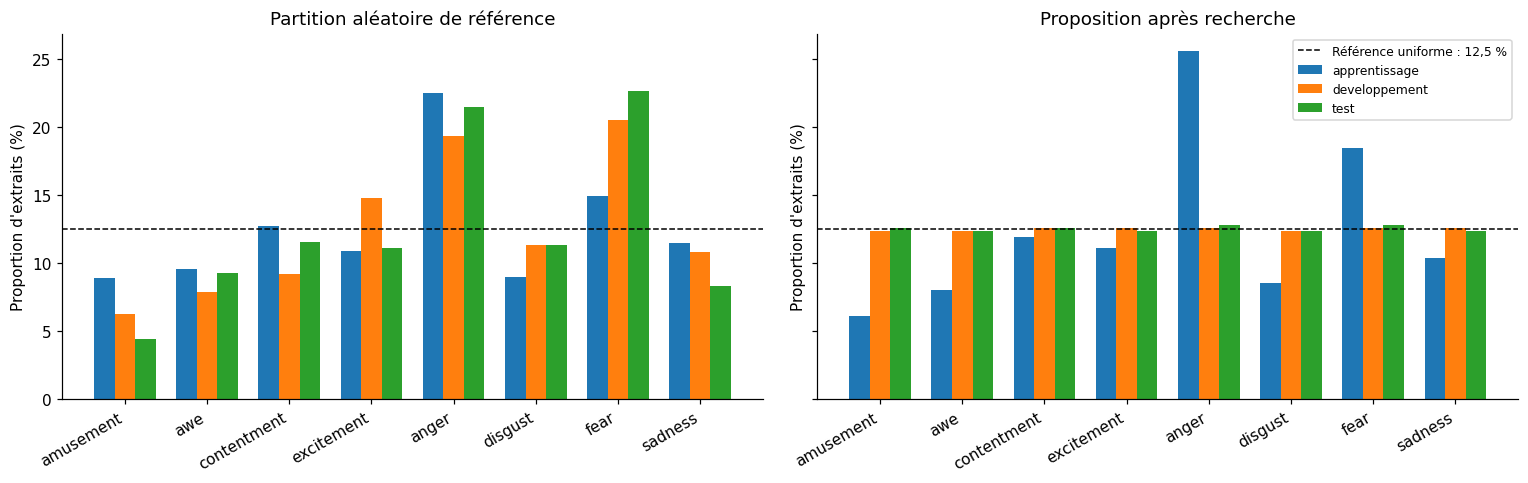

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
x = np.arange(len(emotions))
largeur = 0.25
for i, nom in enumerate(noms_ensembles):
    axes[0].bar(x + (i - 1) * largeur, proportions_aleatoires[i], largeur, label=nom)
    axes[1].bar(x + (i - 1) * largeur, proportions_ensembles.loc[nom], largeur, label=nom)
for ax, titre in zip(axes, ["Partition aléatoire de référence", "Proposition après recherche"]):
    ax.axhline(12.5, color="black", linestyle="--", linewidth=1, label="Référence uniforme : 12,5 %")
    ax.set_xticks(x, emotions, rotation=30, ha="right")
    ax.set(title=titre, ylabel="Proportion d'extraits (%)")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(dossier_resultats / "03_comparaison_partitions.png", dpi=160)
plt.show()

### Interprétation de la proposition

Le développement et le test sont proches de la référence uniforme. **En contrepartie, l'apprentissage reste déséquilibré et peut l'être davantage que dans la partition aléatoire.** Les exemples des classes rares affectés au développement et au test ne sont plus disponibles pour l'apprentissage.

Il n'est pas possible de rendre les trois ensembles parfaitement uniformes tout en conservant tous les extraits d'un corpus globalement déséquilibré. Cette étude privilégie l'équilibre du développement et du test et documente le déséquilibre restant dans l'apprentissage. Pour la modélisation, une pondération des classes pourra être calculée uniquement à partir de l'apprentissage.

## 9. Exporter les résultats et les listes candidates

Les exports contiennent les tables d'analyse, les listes de films, un manifeste des extraits et les paramètres de la recherche. Aucun fichier multimédia n'est déplacé.

Les fichiers sont sauvegardés sous `partitions/candidate_20261019/` et peuvent être réutilisés pour les expériences suivantes.

In [10]:
donnees.to_csv(dossier_resultats / "inventaire_extraits.csv", index=False, encoding="utf-8")
repartition_globale.to_csv(dossier_resultats / "repartition_emotions.csv", encoding="utf-8")
resume_films.to_csv(dossier_resultats / "resume_films.csv", encoding="utf-8")
statistiques_par_emotion.to_csv(dossier_resultats / "durees_par_emotion.csv", encoding="utf-8")
table_films.to_csv(dossier_resultats / "effectifs_par_film_et_emotion.csv", encoding="utf-8")
resume_ensembles.to_csv(dossier_partition / "resume_ensembles.csv", encoding="utf-8")
effectifs_ensembles.to_csv(dossier_partition / "effectifs_emotions.csv", encoding="utf-8")
proportions_ensembles.to_csv(dossier_partition / "proportions_emotions.csv", encoding="utf-8")
comparaison.to_csv(dossier_partition / "comparaison_aleatoire.csv", encoding="utf-8")

for nom in noms_ensembles:
    films = sorted(film for film, ensemble in affectation_films.items() if ensemble == nom)
    (dossier_partition / f"films_{nom}.txt").write_text("\n".join(films) + "\n", encoding="utf-8")

manifest = donnees[["video_id", "film_id", "ensemble", "emotion", "duration", "annotation"]].copy()
manifest["audio"] = "movie/audio/" + manifest["film_id"] + "/" + manifest["video_id"] + ".mp3"
manifest["video"] = "movie/video/" + manifest["film_id"] + "/" + manifest["video_id"] + ".mp4"
manifest.to_csv(dossier_partition / "manifest_extraits.csv", index=False, encoding="utf-8")
empreinte = hashlib.sha256("\n".join(donnees["annotation"] + ":" + donnees["sha256_annotation"]).encode()).hexdigest()
parametres = {
    "statut": "PARTITION_EXPERIMENTALE_PERSONNELLE", "graine": graine,
    "nombre_departs": nombre_departs, "echanges_par_depart": nombre_echanges,
    "tailles_films": dict(zip(noms_ensembles, tailles_films.tolist())),
    "nombre_extraits": len(donnees), "nombre_films": len(table_films),
    "ordre_emotions": emotions, "score_aleatoire": score_partition(comptages_aleatoires),
    "score_propose": meilleur_score, "empreinte_annotations_sha256": empreinte,
    "critere": "Dev/test : ecart quadratique a 1/8 ; apprentissage : 0.25 * ecart a la distribution globale ; tailles extraits : 0.05 * ecart relatif quadratique ; 100 par classe absente.",
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__},
    "controles": controles,
}
(dossier_partition / "parametres.json").write_text(json.dumps(parametres, indent=2, ensure_ascii=False), encoding="utf-8")
(dossier_partition / "README.md").write_text(
    "# Proposition de partition\n\nPartition expérimentale retenue pour cette étude.\n\n"
    "250 films d'apprentissage, 50 de développement et 50 de test. "
    "Aucun film ne figure dans plusieurs ensembles. "
    "Les mêmes listes seront utilisées pour comparer les modèles.\n\n"
    "Les chemins du manifeste sont relatifs au dossier PROJET_SID_2026. "
    "Les listes .txt sont triées et les identifiants doivent être lus comme des chaînes pour conserver les zéros initiaux.\n",
    encoding="utf-8")
print("Résultats et figures :", dossier_resultats)
print("Listes candidates :", dossier_partition)

Résultats et figures : /Users/lihanchen/Desktop/M2/DM_Projet/reconnaissance-emotions/resultats/analyse_donnees
Listes candidates : /Users/lihanchen/Desktop/M2/DM_Projet/reconnaissance-emotions/partitions/candidate_20261019


## 10. Synthèse et limites

La synthèse suivante est produite à partir des résultats calculés, puis sauvegardée en Markdown. Les expériences comparatives utiliseront ces mêmes listes.

In [11]:
def tableau_markdown(table, decimales=2):
    table = table.reset_index()
    lignes = ["| " + " | ".join(map(str, table.columns)) + " |", "| " + " | ".join(["---"] * len(table.columns)) + " |"]
    for valeurs in table.itertuples(index=False, name=None):
        cellules = [f"{v:.{decimales}f}" if isinstance(v, (float, np.floating)) else str(v) for v in valeurs]
        lignes.append("| " + " | ".join(cellules) + " |")
    return "\n".join(lignes)

synthese = f"""# Synthèse de l'analyse des données

## Corpus observé

Le dossier contient **{len(donnees)} extraits de {len(table_films)} films**, soit **{donnees['duration'].sum()/3600:.2f} heures** au total. La durée médiane est de **{donnees['duration'].median():.2f} secondes**, avec un minimum de {donnees['duration'].min():.2f} s et un maximum de {donnees['duration'].max():.2f} s.

Le support annonce 3439 extraits. L'écart avec l'effectif observé doit être signalé ; le seul dossier analysé ne permet pas d'en établir la cause.

Les contrôles structurels vérifient les labels, les identifiants, les durées et la correspondance des fichiers audio/vidéo/JSON. Ils ne remplacent pas une vérification du décodage ou de la qualité des médias.

## Déséquilibre global

{tableau_markdown(repartition_globale)}

La classe la plus représentée est **{effectifs.idxmax()}** ({effectifs.max()} extraits), contre **{effectifs.idxmin()}** ({effectifs.min()}) pour la moins représentée : un rapport de **{rapport_desequilibre:.2f}**.

## Proposition de partition par film

La partition ci-dessous est retenue pour cette étude. Aucun film n'apparaît dans plusieurs ensembles et aucun extrait n'est supprimé ou dupliqué.

{tableau_markdown(resume_ensembles)}

### Effectifs par émotion

{tableau_markdown(effectifs_ensembles, 0)}

### Proportions par émotion (%)

{tableau_markdown(proportions_ensembles)}

### Comparaison avec une partition aléatoire

{tableau_markdown(comparaison)}

La recherche utilise {nombre_departs} départs et {nombre_echanges} échanges tentés par départ, avec la graine {graine}. Elle privilégie l'équilibre des classes du développement et du test, tout en limitant les écarts de taille et la modification de la distribution d'apprentissage. Le critère passe de {score_partition(comptages_aleatoires):.6f} à {meilleur_score:.6f}.

## Limites et suite

Le développement et le test sont presque uniformes, mais l'apprentissage reste déséquilibré : **{proportions_ensembles.loc['apprentissage', 'anger']:.2f} %** d'anger contre **{proportions_ensembles.loc['apprentissage', 'amusement']:.2f} %** d'amusement. Cette priorité donnée à l'évaluation augmente ici le déséquilibre de l'apprentissage par rapport à la partition aléatoire. Ce compromis est documenté dans cette analyse. Une pondération des classes pour les modèles pourra être calculée sur l'apprentissage seul.

- L'équilibre parfait n'est pas garanti : l'affectation porte sur des films entiers, dont les effectifs et les émotions diffèrent.
- La recherche est heuristique et ses pondérations sont des paramètres de cette étude.
- Les trois ensembles contiennent toutes les émotions ; leurs proportions exactes sont indiquées ci-dessus.
- Cette analyse n'entraîne aucun modèle et ne mesure aucune performance sur le test.
- Conserver cette partition, ajuster les modèles sur l'apprentissage et le développement ; réserver le test à l'évaluation finale.
"""
(dossier_docs / "synthese_analyse_donnees.md").write_text(synthese, encoding="utf-8")
from IPython.display import Markdown
display(Markdown(synthese))

# Synthèse de l'analyse des données

## Corpus observé

Le dossier contient **3088 extraits de 350 films**, soit **6.98 heures** au total. La durée médiane est de **6.42 secondes**, avec un minimum de 4.00 s et un maximum de 29.82 s.

Le support annonce 3439 extraits. L'écart avec l'effectif observé doit être signalé ; le seul dossier analysé ne permet pas d'en établir la cause.

Les contrôles structurels vérifient les labels, les identifiants, les durées et la correspondance des fichiers audio/vidéo/JSON. Ils ne remplacent pas une vérification du décodage ou de la qualité des médias.

## Déséquilibre global

| emotion | nombre_extraits | proportion_pct |
| --- | --- | --- |
| amusement | 244 | 7.90 |
| awe | 286 | 9.26 |
| contentment | 373 | 12.08 |
| excitement | 354 | 11.46 |
| anger | 677 | 21.92 |
| disgust | 297 | 9.62 |
| fear | 519 | 16.81 |
| sadness | 338 | 10.95 |

La classe la plus représentée est **anger** (677 extraits), contre **amusement** (244) pour la moins représentée : un rapport de **2.77**.

## Proposition de partition par film

La partition ci-dessous est retenue pour cette étude. Aucun film n'apparaît dans plusieurs ensembles et aucun extrait n'est supprimé ou dupliqué.

| ensemble | nombre_films | nombre_extraits | duree_totale_s | duree_moyenne_s |
| --- | --- | --- | --- | --- |
| apprentissage | 250 | 2213 | 18022.13 | 8.14 |
| developpement | 50 | 437 | 3516.26 | 8.05 |
| test | 50 | 438 | 3602.81 | 8.23 |

### Effectifs par émotion

| ensemble | amusement | awe | contentment | excitement | anger | disgust | fear | sadness |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| apprentissage | 135 | 178 | 263 | 245 | 566 | 189 | 408 | 229 |
| developpement | 54 | 54 | 55 | 55 | 55 | 54 | 55 | 55 |
| test | 55 | 54 | 55 | 54 | 56 | 54 | 56 | 54 |

### Proportions par émotion (%)

| ensemble | amusement | awe | contentment | excitement | anger | disgust | fear | sadness |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| apprentissage | 6.10 | 8.04 | 11.88 | 11.07 | 25.58 | 8.54 | 18.44 | 10.35 |
| developpement | 12.36 | 12.36 | 12.59 | 12.59 | 12.59 | 12.36 | 12.59 | 12.59 |
| test | 12.56 | 12.33 | 12.56 | 12.33 | 12.79 | 12.33 | 12.79 | 12.33 |

### Comparaison avec une partition aléatoire

| ensemble | ecart_moyen_uniforme_aleatoire_points | ecart_moyen_uniforme_propose_points |
| --- | --- | --- |
| apprentissage | 3.18 | 4.75 |
| developpement | 4.28 | 0.11 |
| test | 4.78 | 0.17 |

La recherche utilise 24 départs et 3000 échanges tentés par départ, avec la graine 20261019. Elle privilégie l'équilibre des classes du développement et du test, tout en limitant les écarts de taille et la modification de la distribution d'apprentissage. Le critère passe de 0.047585 à 0.000607.

## Limites et suite

Le développement et le test sont presque uniformes, mais l'apprentissage reste déséquilibré : **25.58 %** d'anger contre **6.10 %** d'amusement. Cette priorité donnée à l'évaluation augmente ici le déséquilibre de l'apprentissage par rapport à la partition aléatoire. Ce compromis est documenté dans cette analyse. Une pondération des classes pour les modèles pourra être calculée sur l'apprentissage seul.

- L'équilibre parfait n'est pas garanti : l'affectation porte sur des films entiers, dont les effectifs et les émotions diffèrent.
- La recherche est heuristique et ses pondérations sont des paramètres de cette étude.
- Les trois ensembles contiennent toutes les émotions ; leurs proportions exactes sont indiquées ci-dessus.
- Cette analyse n'entraîne aucun modèle et ne mesure aucune performance sur le test.
- Conserver cette partition, ajuster les modèles sur l'apprentissage et le développement ; réserver le test à l'évaluation finale.
